In [1]:
#imports
import tweepy
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from spellchecker import SpellChecker
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score
from sqlalchemy import create_engine
from pymongo import MongoClient
import mysql.connector


In [2]:
# Twitter/X API credentials come from environment variables - see .env.example.
# Credentials are never hardcoded in a published notebook.
import os
api_key             = os.environ.get("TWITTER_API_KEY")
api_secret          = os.environ.get("TWITTER_API_SECRET")
bearer_token        = os.environ.get("TWITTER_BEARER_TOKEN")
access_token        = os.environ.get("TWITTER_ACCESS_TOKEN")
access_token_secret = os.environ.get("TWITTER_ACCESS_TOKEN_SECRET")

# The X API v2 recent-search endpoint now requires a paid tier, so live collection is
# off by default. Everything downstream runs from the tweets saved in data/.
LIVE_COLLECTION = bool(bearer_token) and os.environ.get("LIVE_COLLECTION") == "1"


In [3]:
if LIVE_COLLECTION:
    #Authetication twitter
    auth = tweepy.OAuthHandler(api_key, api_secret)
    auth.set_access_token(access_token, access_token_secret)
    #Tweepy 
    client = tweepy.Client(bearer_token=bearer_token)
    #Buat API object
    api = tweepy.API(auth, wait_on_rate_limit=True)


In [4]:
if LIVE_COLLECTION:
    #Verify API
    try:
        api.verify_credentials()
        print("Authentication OK")
    except Exception as e:
        print(f"Error during authentication: {e}")


In [5]:
#Mencari tag film deapool and wolavrine (english/exclude retweet)
query = "#DeadpoolAndWolverine -is:retweet lang:en"

In [6]:
if LIVE_COLLECTION:
    #Ambil tweets terbaru
    response = client.search_recent_tweets(
        query=query,
        max_results=100,
        tweet_fields=["created_at", "text", "public_metrics", "author_id"]
    )


In [7]:
if LIVE_COLLECTION:
    #Bikin list
    tweet_data = []
    if response.data:
        for tweet in response.data:
            tweet_data.append({
                "created_at": tweet.created_at,
                "text": tweet.text,
                "retweets": tweet.public_metrics["retweet_count"],
                "likes": tweet.public_metrics["like_count"],
                "author_id": tweet.author_id
            })
    #Konversi list jadi dataframe
    raw_df = pd.DataFrame(tweet_data)


In [8]:
# Load the collected tweets (saved during the original run)
from pathlib import Path
maindf = pd.read_csv(Path.cwd().parent / "data" / "deadpool_wolverine_raw_tweets.csv")
print(f"{len(maindf)} tweets loaded")
maindf.head()


100 tweets loaded


,created_at,text,retweets,likes,author_id
0,2024-11-23 08:20:08+00:00,Spying you need help recovering from hackers \...,0,1,1545873185958141955
1,2024-11-23 08:00:03+00:00,"Wolverine ""Wade, you wanna be an annoying pric...",0,0,1778284910098141184
2,2024-11-23 07:56:31+00:00,@MCUFilmNews @DanielRPK Yes reportedly till he...,0,0,560926939
3,2024-11-23 07:53:45+00:00,When you know characters can't die it's a taci...,0,0,27684504
4,2024-11-23 07:52:15+00:00,⛄️❄️snowball fight\n#deadclaws #poolverine #De...,4,36,1607946962871128069


In [9]:
#PREPROCESSING
#Spellchecker
spell = SpellChecker()
stop_words = set(stopwords.words('english'))
analyzer = SentimentIntensityAnalyzer()

In [10]:
#Pembersihan data
def preprocess_text(text):
    #Buang URL, @, angka, dan tanda baca
    text = re.sub(r"http\S+|www\S+|@\w+|#\w+|\d+|[^A-Za-z0-9\s]", "", text)    
    #Tokenization, konversi huruf menjadi huruf kecil, dan normalisasi kata
    words = word_tokenize(text.lower())
    corrected_words = [spell.correction(word) for word in words]
    #Membuang value
    corrected_words = [word for word in corrected_words if word is not None]
    #Membuang stopwords
    filtered_words = [word for word in corrected_words if word not in stop_words]
    #Gabungkan kalimat bersih
    cleaned_text = ' '.join(filtered_words)
    return cleaned_text
#Simpan dalam kolom baru
maindf['cleaned_text'] = maindf['text'].apply(preprocess_text)


In [11]:
#ANALISIS SENTIMEN
#Definisi sentiment analysis
def get_sentiment_score(text):
    #Sentiment popularity dengan vader
    sentiment_score = analyzer.polarity_scores(text)
    #positive, negative, dan neutral
    if sentiment_score['compound'] >= 0.05:
        return 'positive'
    elif sentiment_score['compound'] <= -0.05:
        return 'negative'
    else:
        return 'neutral'
#Simpan hasil dalam kolom baru
maindf['sentiment'] = maindf['cleaned_text'].apply(get_sentiment_score)
maindf.head()

,created_at,text,retweets,likes,author_id,cleaned_text,sentiment
0,2024-11-23 08:20:08+00:00,Spying you need help recovering from hackers \...,0,1,1545873185958141955,spying need help recovering hackers,positive
1,2024-11-23 08:00:03+00:00,"Wolverine ""Wade, you wanna be an annoying pric...",0,0,1778284910098141184,wolverine wade wan na annoying prick side na d...,negative
2,2024-11-23 07:56:31+00:00,@MCUFilmNews @DanielRPK Yes reportedly till he...,0,0,560926939,yes reportedly till,positive
3,2024-11-23 07:53:45+00:00,When you know characters can't die it's a taci...,0,0,27684504,know characters cant die tacit admission zero ...,positive
4,2024-11-23 07:52:15+00:00,⛄️❄️snowball fight\n#deadclaws #poolverine #De...,4,36,1607946962871128069,snowball fight,negative


In [12]:
#MODEL NAIVE BAYES
#Pembagian variabel
X = maindf['cleaned_text']
y = maindf['sentiment']
#Konversi text manjadi fitur
vectorizer = CountVectorizer()
X_vectorized = vectorizer.fit_transform(X)
#Pembagian data
X_train, X_test, y_train, y_test = train_test_split(X_vectorized, y, test_size=0.2, random_state=42)

In [13]:
#Model naive bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)

In [14]:
#Evaluasi model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.86      1.00      0.92         6
    positive       0.92      0.92      0.92        13

    accuracy                           0.90        20
   macro avg       0.59      0.64      0.62        20
weighted avg       0.86      0.90      0.88        20



<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


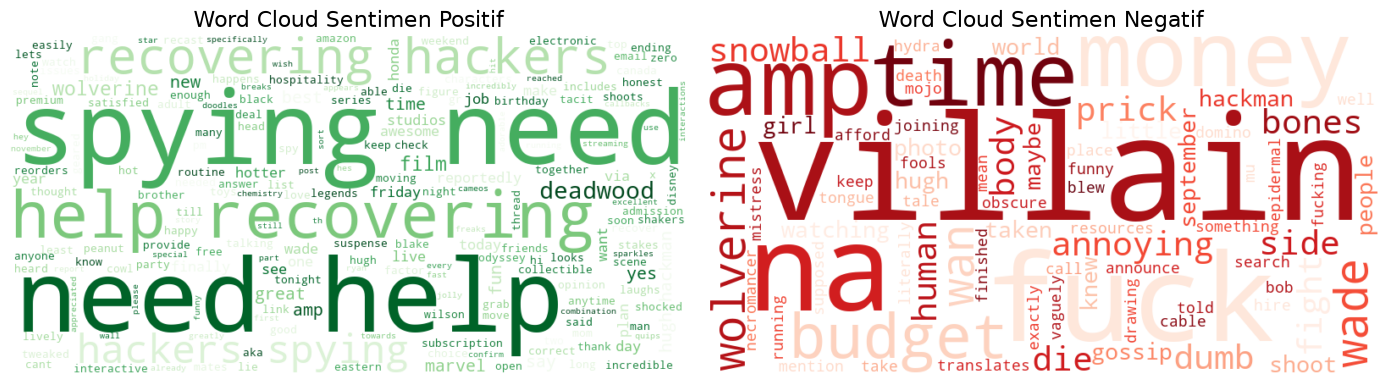

In [15]:
#VISUALISASI WORD CLOUD
#Pemisahan data positive dan negative
positive_text = " ".join(maindf[maindf['sentiment'] == 'positive']['cleaned_text'])
negative_text = " ".join(maindf[maindf['sentiment'] == 'negative']['cleaned_text'])
#Word cloud postive
positive_wordcloud = WordCloud(
    background_color='white',
    width=800,
    height=400,
    max_words=200,
    colormap='Greens'
).generate(positive_text)
#Word cloud negative
negative_wordcloud = WordCloud(
    background_color='white',
    width=800,
    height=400,
    max_words=200,
    colormap='Reds'
).generate(negative_text)

#Visualisasi word cloud
plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.imshow(positive_wordcloud, interpolation='bilinear')
plt.title('Word Cloud Sentimen Positif', fontsize=16)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(negative_wordcloud, interpolation='bilinear')
plt.title('Word Cloud Sentimen Negatif', fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

In [16]:
# Load results into AWS Redshift (optional - needs a live cluster)
# Credentials come from the environment; the original cluster no longer exists.
import os
from sqlalchemy import create_engine

rs_host = os.environ.get("REDSHIFT_HOST")
rs_user = os.environ.get("REDSHIFT_USER")
rs_pass = os.environ.get("REDSHIFT_PASSWORD")
rs_db   = os.environ.get("REDSHIFT_DB", "dev")
rs_port = os.environ.get("REDSHIFT_PORT", "5439")

if all([rs_host, rs_user, rs_pass]):
    engine = create_engine(f"postgresql+psycopg2://{rs_user}:{rs_pass}@{rs_host}:{rs_port}/{rs_db}")
    maindf.to_sql("tweets", con=engine, index=False, if_exists="replace")
    print("Uploaded to Redshift")
else:
    print("Redshift credentials not set - skipping warehouse load")


Redshift credentials not set - skipping warehouse load


In [17]:
# Load results into MySQL (optional - needs a local server)
import os
from sqlalchemy import create_engine

my_host = os.environ.get("MYSQL_HOST", "localhost")
my_user = os.environ.get("MYSQL_USER", "root")
my_pass = os.environ.get("MYSQL_PASSWORD")
my_db   = os.environ.get("MYSQL_DATABASE", "twitter")

if my_pass:
    engine = create_engine(f"mysql+mysqlconnector://{my_user}:{my_pass}@{my_host}/{my_db}")
    maindf.to_sql("tweets", con=engine, index=False, if_exists="replace")
    print(f"Data written to MySQL database '{my_db}'")
else:
    print("MYSQL_PASSWORD not set - skipping MySQL load")


MYSQL_PASSWORD not set - skipping MySQL load
